# Module A: Price Advisor
Goal: predict adr (nightly rate) for a booking. 

Intuition: you’re teaching a model how a revenue manager prices rooms. Room type, month, party size and lead time all push the rate up or down. The business decision is the suggested nightly rate for a new booking.



## 0. Setup

In [7]:
import sys
sys.path.insert(0, "..")          # project root, so `src` can be found

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.pipeline import Pipeline
from src._01_code.features import build_preprocessor

In [8]:
# --------- Configurations -----------
RANDOM_STATE = 42
TEST_SIZE = 0.2
TARGETS = ["is_canceled", "adr"]

df = pd.read_csv("../data/clean/hotel_clean.csv")


In [ ]:
# Sanity check: duplicate bookings split across train and test would flatter flexible models (RF, KNN, boosting)
print("Rows:", len(df), "| duplicate rows:", df.duplicated().sum())

In [9]:
# Train test split 

train_df, test_df = train_test_split(
    df, test_size=TEST_SIZE, stratify=df["is_canceled"], random_state=RANDOM_STATE
)

#Keep bookings with a real price
n_train_before, n_test_before = len(train_df), len(test_df)
train_df = train_df[train_df["adr"] > 0 ]
test_df = test_df[test_df["adr"] > 0 ]
print (f"train: {n_train_before:,} -> {len(train_df):,} | test: {n_test_before:,} -> {len(test_df):,} ")

# Features exclude BOTH targets: adr is the target for Module A, is_canceled for Module B
X_train = train_df.drop(columns=TARGETS)
X_test = test_df.drop(columns=TARGETS)
y_train, y_test = train_df["adr"], test_df["adr"]

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()



train: 69,096 -> 68,280 | test: 17,275 -> 17,039 


In [10]:
# Helper functions & pipeline configuration

def make_pipe(model):
    return Pipeline([
        ("prep", build_preprocessor(num_cols, cat_cols)),
        ("model", model),
    ])

def cv_score(name, pipe, X=None, y=None):
    X = X_train if X is None else X
    y = y_train if y is None else y
    cv = cross_validate(
        pipe, X, y, cv=5, n_jobs=-1,
        scoring={"mae": "neg_mean_absolute_error",
                 "rmse": "neg_root_mean_squared_error",
                 "r2": "r2"},
    )
    return {"model": name,
            "MAE": -cv["test_mae"].mean(),
            "RMSE": -cv["test_rmse"].mean(),
            "R2": cv["test_r2"].mean()}

## 1. Baseline & Linear regression model 

In [11]:
models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
}

results = [cv_score(name, make_pipe(m)) for name, m in models.items()]
leaderboard = pd.DataFrame(results).sort_values("MAE")
leaderboard

,model,MAE,RMSE,R2
1,Linear Regression,21.272858,28.913133,0.669932
0,Mean baseline,38.825589,50.328169,-0.000033


* R² = 0.66 means the model explains about 66% of the variation in ADR. The hotel can read it as “these booking details (dates, room type, guests, lead time, and so on) account for roughly two-thirds of why prices differ.” The other 34% is what the model can’t explain yet. It could be non-linear effects, features we don’t have (events, competitors’ prices) or plain noise.
* RMSE is above the MAE, because squaring punishes big misses, so this gap tells you some bookings have prices far from the average (expensive peak-season rooms, for example)

Text(0, 0.5, 'predicted adr')

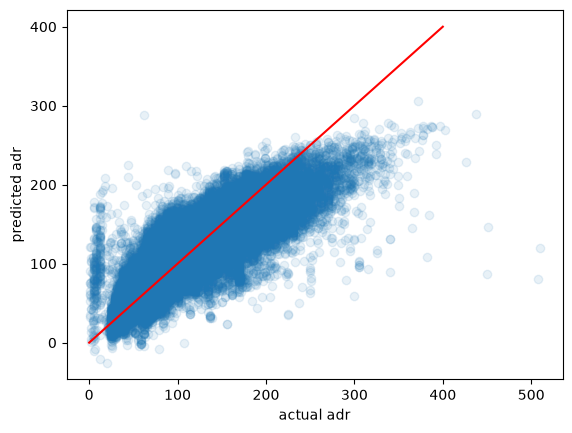

In [12]:
from sklearn.model_selection import cross_val_predict
pred = cross_val_predict(make_pipe(LinearRegression()), X_train, y_train, cv=5, n_jobs=-1)
plt.scatter(y_train, pred, alpha=0.1); plt.plot([0, 400], [0, 400], "r")
plt.xlabel("actual adr"); plt.ylabel("predicted adr")

In [13]:
pipe = make_pipe(LinearRegression())
pipe.fit(X_train, y_train)

names = pipe.named_steps["prep"].get_feature_names_out()
weights = pipe.named_steps["model"].coef_

coef_df = pd.DataFrame({"feature": names, "weight": weights})
coef_df["abs_weight"] = coef_df["weight"].abs()
coef_df.sort_values("abs_weight", ascending=False).head(10)

,feature,weight,abs_weight
104,cat__assigned_room_type_infrequent_sklearn,-129.917599,129.917599
24,cat__arrival_date_month_December,56.871310,56.871310
84,cat__distribution_channel_infrequent_sklearn,-56.172497,56.172497
79,cat__market_segment_infrequent_sklearn,-53.910987,53.910987
26,cat__arrival_date_month_January,-47.842788,47.842788
86,cat__reserved_room_type_B,-44.250113,44.250113
25,cat__arrival_date_month_February,-37.360728,37.360728
35,cat__meal_FB,37.048538,37.048538
92,cat__reserved_room_type_H,35.090128,35.090128
29,cat__arrival_date_month_March,-30.544154,30.544154


In [14]:
num_coef = coef_df[coef_df["feature"].str.startswith("num__")]
num_coef.sort_values("abs_weight", ascending=False).head(10)

,feature,weight,abs_weight
2,num__arrival_date_week_number,-22.270163,22.270163
1,num__arrival_date_year,10.918938,10.918938
0,num__lead_time,-10.017636,10.017636
6,num__adults,3.855852,3.855852
17,num__total_guests,3.596169,3.596169
3,num__arrival_date_day_of_month,3.138179,3.138179
18,num__is_family,2.079803,2.079803
7,num__children,1.544624,1.544624
8,num__babies,-1.169001,1.169001
9,num__is_repeated_guest,-1.044789,1.044789


In [ ]:
print(f"Share of bookings with adr == 0: {(df['adr'] == 0).mean():.2%} ({(df['adr'] == 0).sum():,} rows)")
df.loc[df["adr"] == 0, "market_segment"].value_counts().head()

### Linear Regression: results and interpretation

**Data note.** Module A trains only on bookings with adr > 0 (filter applied after the
shared train/test split). Over 1,000 bookings (roughly 1%) had a price of 0, mostly
Complementary, Groups and Offline TA/TO. These are free or special stays, not market
prices, so they are excluded here (they stay in the cleaned CSV for Module B).

**Result.** 5-fold CV on the training set:
| Model | MAE | RMSE | R² |
|---|---|---|---|
| Mean baseline | 38.83 | 50.33 | 0.00 |
| Linear Regression | 21.27 | 28.91 | 0.670 |

MAE drops by about 45%. Booking details explain about two thirds of the variation in
ADR. The zero-price rows are only about 1% of the data, so they are unlikely to explain the
remaining error. The large gain from tree models later shows it comes mostly from the model's form.

**What the coefficients show.** Numeric features are scaled (weight = change in ADR per
+1 standard deviation); one-hot weights are shifts for that category.
- Season: December is the most expensive month (+57); January (-48), February (-37)
  and March (-31) are the cheapest. Seasonality is strong and is not a straight line
  across the year, which is why month works better as a category than as a number.
- Room type: reserved type B is cheaper (-44), type H more expensive (+35), which
  fits basic vs premium rooms.
- Meal plan: full board adds about 37 (more is included in the rate).
- Lead time: -10 per standard deviation, so earlier bookings are cheaper
  (early-booking discounts).
- Year: +11 per standard deviation, i.e. prices rose from 2015 to 2017.
- Guests: adults and total guests add only about +4, so party size matters little
  compared with season and room.
- The largest weights belong to catch-all "infrequent" groups (rare assigned room
  types -130, rare distribution channels -56, rare market segments -54). These bundle
  many rare categories and need checking before trusting them.

**Caveats on reading weights.**
- Weights are associations, not causes, and correlated features share credit.
  arrival_date_week_number (-22) overlaps strongly with the month columns, so the two
  should be read together, not separately.
- One-hot weights (a full 0 to 1 switch) and scaled numeric weights (a +1 SD change)
  are different kinds of change, so their sizes are not directly comparable.

**Where it fails (predicted vs actual plot).**
- Predictions are squeezed toward the middle: prices of 250-300 are underpredicted
  and cheap rooms overpredicted. The model cannot bend.
- Errors fan out as the price rises, so it is least reliable for peak prices.
- It can still output a few impossible negative prices.
- Interactions (season x room type) and curved effects (e.g. lead time) cannot be
  represented by one weight per feature.

**Takeaway.** A strong, interpretable baseline limited by its straight-line form.

| Model | How it works | Key hyperparameters | Fails when | Needs scaling? |
|---|---|---|---|---|
| Linear Regression | Weighted sum of the features; weights found by least squares | none (no penalty) | Effects are non-linear or interact; correlated features make weights unstable | No for accuracy (only to compare weights) |


## 2. Polynomial Regression


In [16]:
poly_pipe = Pipeline([
    ("prep", build_preprocessor(num_cols, cat_cols, poly_degree=2)),
    ("model", LinearRegression()),
])

results.append(cv_score("Polynomial (deg 2)", poly_pipe))
leaderboard = pd.DataFrame(results).sort_values("MAE")
leaderboard

,model,MAE,RMSE,R2
2,Polynomial (deg 2),20.682788,28.394500,0.681660
1,Linear Regression,21.272858,28.913133,0.669932
0,Mean baseline,38.825589,50.328169,-0.000033


In [17]:
# 1) Count with the formula
n = len(num_cols)
expected = n + n * (n + 1) // 2
print("numeric columns now      :", n)
print("expected after degree 2  :", expected)

# 2) Verify with the real pipeline
prep = build_preprocessor(num_cols, cat_cols, poly_degree=2)
prep.fit(X_train)                                   # learns scaling; builds the column list
names = prep.get_feature_names_out()

n_num_after = sum(name.startswith("num__") for name in names)
print("numeric columns (actual) :", n_num_after)
print("total columns incl. one-hot:", len(names))
print(names[:5])                                    # peek at a few names

numeric columns now      : 20
expected after degree 2  : 230
numeric columns (actual) : 230
total columns incl. one-hot: 378
['num__lead_time' 'num__arrival_date_year' 'num__arrival_date_week_number'
 'num__arrival_date_day_of_month' 'num__stays_in_weekend_nights']


#### Polynomial Regression (degree 2): results and insights

**Setup.** Degree-2 polynomial features on the 20 numeric columns only, inside the
pipeline: impute, scale, polynomial, scale again, then LinearRegression. One-hot
columns are left alone because squaring a 0/1 column adds nothing. The numeric block
grows from 20 to 230 columns (20 originals + 20 squares + 190 pairwise products), and
the full feature matrix grows from 168 to 378 columns.

**Result.** 5-fold CV on the training set:
| Model | MAE | RMSE | R² |
|---|---|---|---|
| Mean baseline | 38.83 | 50.33 | 0.00 |
| Linear Regression | 21.27 | 28.91 | 0.670 |
| Polynomial (deg 2) | 20.68 | 28.39 | 0.682 |

MAE is about 47% below the baseline and about 3% below plain linear regression.

**Insights.**
- The gain is real but small. Adding 210 columns bought only about 0.6 euro of MAE,
  a poor return for a model more than twice as wide.
- It is small because the polynomial step only touches numeric features. The biggest
  weaknesses found earlier (season x room type, rare categories) involve categorical
  columns, which this step cannot combine.
- Squares and products let numeric effects curve and interact (e.g. lead time that
  flattens out, or lead time combined with length of stay).
- Many of the 210 new columns are probably noise. More columns means more freedom to
  memorize the training data, so overfitting risk rises with degree (degree 3 would
  create about 1,770 numeric columns).
- Errors still grow with price, so peak-season bookings remain the hardest to predict.

**Decision.** Keep degree 2 as a candidate, but do not tune further by hand.

| Model | How it works | Key hyperparameters | Fails when | Needs scaling? |
|---|---|---|---|---|
| Polynomial (deg 2) | Adds squares and pairwise products of the numeric features, then fits a linear model | `degree` | Column count explodes with degree and it overfits; here it only touches numeric columns | Yes |


# 3. Ridge, Lasso, ElasticNet

In [18]:
from sklearn.linear_model import RidgeCV, LassoCV, ElasticNetCV

alphas = np.logspace(-3, 2, 20)     # 0.001 ... 100

reg_models = {
    "Ridge (CV alpha)": RidgeCV(alphas=alphas),
    "Lasso (CV alpha)": LassoCV(alphas=alphas, cv=5, max_iter=5000),
    "ElasticNet (CV)":  ElasticNetCV(alphas=alphas, l1_ratio=[0.2, 0.5, 0.8], cv=5, max_iter=5000),
}

for name, m in reg_models.items():
    results.append(cv_score(name, make_pipe(m)))

leaderboard = pd.DataFrame(results).sort_values("MAE")
leaderboard

/Users/hirunadilmith/Learning/Macine Learning/Hotel Booking Intelligence project/01-code/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.358970e+04, tolerance: 1.107e+04
  model = cd_fast.enet_coordinate_descent_gram(
/Users/hirunadilmith/Learning/Macine Learning/Hotel Booking Intelligence project/01-code/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.778735e+05, tolerance: 1.120e+04
  model = cd_fast.enet_coordinate_descent_gram(
/Users/hirunadilmith/Learning/Macine Learning/Hotel Booking Intelligence project/01-code/.venv/lib/python3.14/site-pac

,model,MAE,RMSE,R2
2,Polynomial (deg 2),20.682788,28.394500,0.681660
1,Linear Regression,21.272858,28.913133,0.669932
3,Ridge (CV alpha),21.275409,28.913100,0.669933
4,Lasso (CV alpha),21.279226,28.914840,0.669894
5,ElasticNet (CV),21.291784,28.924393,0.669676
0,Mean baseline,38.825589,50.328169,-0.000033


In [19]:
fitted = {
    "Linear":     make_pipe(LinearRegression()).fit(X_train, y_train),
    "Ridge":      make_pipe(RidgeCV(alphas=alphas)).fit(X_train, y_train),
    "Lasso":      make_pipe(LassoCV(alphas=alphas, cv=5, max_iter=5000)).fit(X_train, y_train),
    "ElasticNet": make_pipe(ElasticNetCV(alphas=alphas, l1_ratio=[0.2, 0.5, 0.8],
                                         cv=5, max_iter=5000)).fit(X_train, y_train),
}

print("Ridge alpha     :", fitted["Ridge"]["model"].alpha_)
print("Lasso alpha     :", fitted["Lasso"]["model"].alpha_)
print("ElasticNet      :", fitted["ElasticNet"]["model"].alpha_, fitted["ElasticNet"]["model"].l1_ratio_)

names = fitted["Linear"]["prep"].get_feature_names_out()
coef_table = pd.DataFrame({k: p["model"].coef_ for k, p in fitted.items()}, index=names)

print("\nWeights exactly 0:\n", (coef_table == 0).sum())
print("\nDropped by Lasso:", coef_table.index[coef_table["Lasso"] == 0].tolist())

coef_table.loc[coef_table["Lasso"].abs().sort_values(ascending=False).head(15).index].round(2)

/Users/hirunadilmith/Learning/Macine Learning/Hotel Booking Intelligence project/01-code/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.238504e+05, tolerance: 1.383e+04
  model = cd_fast.enet_coordinate_descent_gram(
/Users/hirunadilmith/Learning/Macine Learning/Hotel Booking Intelligence project/01-code/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.009411e+05, tolerance: 1.378e+04
  model = cd_fast.enet_coordinate_descent_gram(
/Users/hirunadilmith/Learning/Macine Learning/Hotel Booking Intelligence project/01-code/.venv/lib/python3.14/site-pac

Ridge alpha     : 0.23357214690901212
Lasso alpha     : 0.001
ElasticNet      : 0.001 0.8

Weights exactly 0:
 Linear         0
Ridge          0
Lasso         15
ElasticNet     9
dtype: int64

Dropped by Lasso: ['num__stays_in_weekend_nights', 'cat__arrival_date_month_May', 'cat__country_ARG', 'cat__country_HUN', 'cat__market_segment_Offline TA/TO', 'cat__distribution_channel_TA/TO', 'cat__reserved_room_type_C', 'cat__reserved_room_type_infrequent_sklearn', 'cat__assigned_room_type_A', 'cat__deposit_type_Non Refund', 'cat__agent_15', 'cat__agent_241', 'cat__agent_26', 'cat__agent_410', 'cat__agent_83']


/Users/hirunadilmith/Learning/Macine Learning/Hotel Booking Intelligence project/01-code/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.103504e+04, tolerance: 1.730e+04
  model = cd_fast.enet_coordinate_descent(


,Linear,Ridge,Lasso,ElasticNet
cat__market_segment_infrequent_sklearn,-53.91,-53.80,-59.87,-46.13
cat__assigned_room_type_infrequent_sklearn,-129.92,-101.93,-51.47,-4.19
cat__arrival_date_month_January,-47.84,-45.76,-49.50,-13.74
cat__distribution_channel_infrequent_sklearn,-56.17,-53.65,-47.99,-13.16
cat__meal_FB,37.05,37.03,47.03,35.67
cat__reserved_room_type_B,-44.25,-43.45,-46.01,-39.46
cat__arrival_date_month_February,-37.36,-35.77,-43.05,-11.22
cat__arrival_date_month_March,-30.54,-29.77,-37.66,-18.78
cat__arrival_date_month_August,29.25,28.72,34.22,20.38
cat__reserved_room_type_H,35.09,35.73,31.57,32.81


#### Ridge, Lasso and ElasticNet

**Setup.** Penalized linear models on the plain preprocessor (168 columns); alpha chosen
by cross-validation inside each training fold (RidgeCV, LassoCV, ElasticNetCV).

**Result.** 5-fold CV on the training set:
| Model | MAE | RMSE | R² |
|---|---|---|---|
| Linear Regression | 21.27 | 28.91 | 0.670 |
| Ridge (alpha 0.23) | 21.28 | 28.91 | 0.670 |
| Lasso (alpha 0.001) | 21.28 | 28.91 | 0.670 |
| ElasticNet (alpha 0.001, l1_ratio 0.8) | 21.29 | 28.92 | 0.670 |

**Insights.**
- Regularization did not improve accuracy: all models tie within 0.02 euro. With
  ~68k rows and 168 features there is little overfitting to remove. Lasso and ElasticNet
  chose the smallest alpha in the grid (0.001) and Ridge chose 0.23, so the lower edge of the
  grid could be extended, but the tied scores suggest it would change little.
- Lasso set 15 weights to exactly 0 (ElasticNet 9): a mix of rare countries and agents,
  some room types, a month, a market segment and distribution channel, the non-refund
  deposit type and weekend nights, so it works as feature selection. Ridge set none to 0.
- Correlated features share credit unpredictably. The weight of
  assigned_room_type_infrequent was -130 (Linear), -102 (Ridge), -51 (Lasso) and -4
  (ElasticNet), so it should not be interpreted on its own.
- ElasticNet and Lasso showed convergence warnings, so their coefficients are less
  reliable than their predictions.

**Takeaway.** Regularization is not what improves this model. Its value here is
stability and feature selection. The remaining error needs non-linear models (trees).

| Model | How it works | Key hyperparameters | Fails when | Needs scaling? |
|---|---|---|---|---|
| Ridge | Linear regression + penalty on squared weights | alpha | Relationships are non-linear; keeps all features | Yes |
| Lasso | Linear regression + penalty on absolute weights; zeroes weak features | alpha | Correlated features (drops one arbitrarily); non-linear data | Yes |
| ElasticNet | Mix of both penalties | alpha, l1_ratio | Non-linear data; needs more iterations to converge | Yes |

# 4. KNN & SVR

In [20]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor

# 20k sample from the TRAIN set only (the test set stays untouched)
sample = train_df.sample(20_000, random_state=RANDOM_STATE)
X_s = sample.drop(columns=TARGETS)
y_s = sample["adr"]

knn_pipe = make_pipe(
    KNeighborsRegressor(n_neighbors=10, weights="distance")
)

svr_pipe = make_pipe(
    TransformedTargetRegressor(
        regressor=SVR(kernel="rbf", C=10, epsilon=0.1),
        transformer=StandardScaler(),     # scales y inside, predictions come back in euros
    )
)

results_small = [
    cv_score("KNN (k=10, 20k)", knn_pipe, X_s, y_s),
    cv_score("SVR (rbf, 20k)",  svr_pipe, X_s, y_s),
]
pd.DataFrame(results_small).sort_values("MAE")

,model,MAE,RMSE,R2
1,"SVR (rbf, 20k)",12.594748,19.275439,0.851306
0,"KNN (k=10, 20k)",18.946581,27.425041,0.699179


In [21]:
results_small.append(cv_score("Linear (20k)", make_pipe(LinearRegression()), X_s, y_s))
pd.DataFrame(results_small).sort_values("MAE")

,model,MAE,RMSE,R2
1,"SVR (rbf, 20k)",12.594748,19.275439,0.851306
0,"KNN (k=10, 20k)",18.946581,27.425041,0.699179
2,Linear (20k),21.299853,28.896322,0.666001


In [22]:
knn_rows = []
for k in [3, 10, 25, 50]:
    pipe = make_pipe(KNeighborsRegressor(n_neighbors=k, weights="distance"))
    knn_rows.append(cv_score(f"KNN (k={k})", pipe, X_s, y_s))

knn_k = pd.DataFrame(knn_rows)
knn_k

,model,MAE,RMSE,R2
0,KNN (k=3),19.020237,28.219521,0.681491
1,KNN (k=10),18.946581,27.425041,0.699179
2,KNN (k=25),20.267190,28.710890,0.670322
3,KNN (k=50),21.572682,30.170597,0.635953


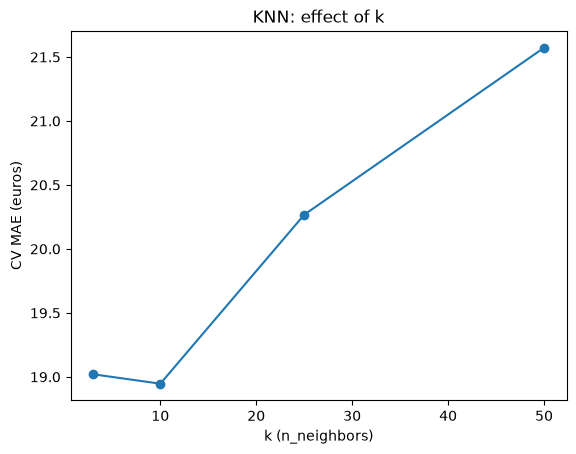

In [23]:
knn_k["k"] = [3, 10, 25, 50]
plt.plot(knn_k["k"], knn_k["MAE"], marker="o")
plt.xlabel("k (n_neighbors)"); plt.ylabel("CV MAE (euros)")
plt.title("KNN: effect of k")
plt.show()

### KNN and SVR: results and insights

**Setup.** Both models use the same preprocessor as before (impute, scale, one-hot) inside a pipeline, trained on a random 20,000-row sample of the training set because they are slow on the full 68k rows. SVR (RBF kernel, C=10, epsilon=0.1) also scales the target with `TransformedTargetRegressor`, so epsilon is in standardized units and predictions still come back in euros. `cv_score` was changed to accept a data argument, so these models are scored on the sample and not silently on all rows.

**Result.** 5-fold CV on the same 20k sample:
| Model | MAE | RMSE | R² |
|---|---|---|---|
| Linear Regression (20k) | 21.30 | 28.90 | 0.666 |
| KNN (k=10) | 18.95 | 27.43 | 0.699 |
| SVR (RBF) | **12.59** | **19.28** | **0.851** |

Linear Regression on 20k (MAE 21.30) matches the 68k result (21.27), so the sample size is not what drives the differences. The comparison is fair.

**Effect of k in KNN.**
| k | 3 | 10 | 25 | 50 |
|---|---|---|---|---|
| MAE | 19.02 | **18.95** | 20.27 | 21.57 |

- Large k underfits (high bias). At k=50 neighbours from different seasons and room types are averaged together, so predictions drift toward the overall mean and the model becomes worse than linear regression.
- Small k is noisier (higher variance). k=3 is only slightly worse than k=10, so the variance penalty is mild here.
- k=10 is the best of the values tried. Tuning k cannot close the gap to SVR.

**Insights.**
- SVR lowers MAE by about 41% versus linear regression (21.30 to 12.59) and raises R² from 0.67 to 0.85. The pricing signal is clearly non-linear.
- The RBF kernel builds a smooth curved price surface, which lets it capture interactions (for example season x room type) and curved effects (for example lead time) that one weight per feature cannot.
- KNN improves on linear regression by only about 11%. Most columns are one-hot, so "similar bookings" mostly means "same categories", and the numeric signal (lead time, guests) is diluted in the distance. This is a structural limit, not a tuning problem.
- RMSE is about 1.5x MAE for SVR, so large misses still exist, most likely for high peak-season prices.

**Trade-offs.**
- SVR took about 2.5 minutes for KNN and SVR together on 20k rows (5 folds). Training time grows much faster than linearly with rows, so it does not scale to the full data.
- SVR has no readable weights, so it is harder to explain to a hotel manager than a linear model.
- KNN has no training step, but each prediction compares against all stored rows, which is slow at scale.

**Takeaway.** SVR is the most accurate model so far and shows that non-linear models are worth it. Because it is slow and hard to interpret, the tree models are the next test: they should capture the same interactions, run on all 68k rows, and give feature importances.

| Model | How it works | Key hyperparameters | Fails when | Needs scaling? |
|---|---|---|---|---|
| KNN | Averages the price of the k most similar bookings | `n_neighbors`, `weights`, distance `p` | Many one-hot or irrelevant features dilute distance; slow prediction on big data | Yes |
| SVR | Fits a smooth curve (RBF kernel) that ignores errors within epsilon | `C`, `epsilon`, `gamma`, `kernel` | Large datasets (slow); sensitive to the scale of X and y; hard to interpret | Yes (X and y) |

# 5. Tree models (Decision Tree, Random Forest, Gradient Boosting)

In [24]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

tree_models = {
    "Decision Tree (depth 8)": DecisionTreeRegressor(max_depth=8, min_samples_leaf=20,
                                                     random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                           random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}

for name, m in tree_models.items():
    results.append(cv_score(name, make_pipe(m)))   # full 68k rows, no sample needed

leaderboard = pd.DataFrame(results).sort_values("MAE")
leaderboard

,model,MAE,RMSE,R2
7,Random Forest,9.973527,17.039317,0.885358
8,Hist Gradient Boosting,11.405214,17.363339,0.880967
6,Decision Tree (depth 8),18.320291,26.127148,0.730414
2,Polynomial (deg 2),20.682788,28.394500,0.681660
1,Linear Regression,21.272858,28.913133,0.669932
3,Ridge (CV alpha),21.275409,28.913100,0.669933
4,Lasso (CV alpha),21.279226,28.914840,0.669894
5,ElasticNet (CV),21.291784,28.924393,0.669676
0,Mean baseline,38.825589,50.328169,-0.000033


### Decision Tree, Random Forest and Gradient Boosting: results and insights

**Setup.** All three run on the full 68k training rows through the same pipeline (trees do not need scaling, so the scaler is harmless). Decision Tree: `max_depth=8`, `min_samples_leaf=20`. Random Forest: 200 trees, `min_samples_leaf=5`. Gradient boosting: `HistGradientBoostingRegressor` with default settings (untuned).

**Result.** 5-fold CV on the training set:
| Model | MAE | RMSE | R² |
|---|---|---|---|
| Linear Regression | 21.27 | 28.91 | 0.670 |
| Decision Tree (depth 8) | 18.32 | 26.13 | 0.730 |
| Hist Gradient Boosting | 11.41 | 17.36 | 0.881 |
| Random Forest | **9.97** | **17.04** | **0.885** |

Random Forest cuts MAE by about 53% versus linear regression and by about 46% versus a single tree.

**Insights.**
- Trees find non-linear effects and interactions (for example season x room type) on their own, which is what the linear models could not do. This confirms the earlier finding that the remaining error came from the model's form.
- A single depth-8 tree is only modestly better than linear regression. Averaging 200 trees in a Random Forest almost halves its error, which shows how much of a single tree's error is variance.
- Random Forest beat gradient boosting here. The boosting model used default settings (100 rounds), so it is probably underfit, and tuning may change the ranking.
- RMSE is about 1.5-1.7x MAE for the ensembles (1.7x for Random Forest, 1.5x for gradient boosting), so large misses still exist, probably for high-priced peak bookings. This is checked in the residual analysis.
- Ensembles are less interpretable than linear weights. Feature importance will be used to explain what drives price.

| Model | How it works | Key hyperparameters | Fails when | Needs scaling? |
|---|---|---|---|---|
| Decision Tree | A flowchart of yes/no splits; each leaf predicts the mean price | `max_depth`, `min_samples_leaf` | Unlimited depth memorizes the training set; unstable to small data changes | No |
| Random Forest | Many trees on bootstrap samples, predictions averaged | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features` | Cannot predict beyond the price range seen in training; large and slow to predict | No |
| Gradient Boosting | Trees built one after another, each fixing the previous errors | `learning_rate`, `max_iter`, `max_leaf_nodes`, `min_samples_leaf` | Too many rounds fit the noise; sensitive to tuning | No |

# 6. Tune the top 2

In [25]:
from scipy.stats import randint, loguniform
from sklearn.model_selection import RandomizedSearchCV

searches = {
    "Random Forest": (
        RandomForestRegressor(random_state=RANDOM_STATE),
        {
            "model__n_estimators": randint(100, 400),
            "model__max_depth": [None, 15, 25, 40],
            "model__min_samples_leaf": randint(1, 15),
            "model__max_features": [0.3, 0.5, 0.8, 1.0],
        },
    ),
    "Hist Gradient Boosting": (
        HistGradientBoostingRegressor(random_state=RANDOM_STATE),
        {
            "model__learning_rate": loguniform(0.02, 0.3),
            "model__max_iter": randint(200, 800),
            "model__max_leaf_nodes": randint(15, 80),
            "model__min_samples_leaf": randint(10, 80),
            "model__l2_regularization": loguniform(1e-3, 10),
        },
    ),
}

best_pipes = {}
for name, (model, params) in searches.items():
    search = RandomizedSearchCV(
        make_pipe(model), params, n_iter=12, cv=3,
        scoring="neg_mean_absolute_error",
        n_jobs=-1, random_state=RANDOM_STATE, verbose=1,
    )
    search.fit(X_train, y_train)
    best_pipes[name] = search.best_estimator_
    print(name, "| search CV MAE:", -search.best_score_)
    print("  best params:", search.best_params_)

# Re-score the winners with the SAME 5-fold protocol as every other row
for name, pipe in best_pipes.items():
    results.append(cv_score(f"{name} (tuned)", pipe))

pd.DataFrame(results).sort_values("MAE").head(6)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Random Forest | search CV MAE: 9.840126763221358
  best params: {'model__max_depth': 40, 'model__max_features': 1.0, 'model__min_samples_leaf': 3, 'model__n_estimators': 249}
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Hist Gradient Boosting | search CV MAE: 9.583373164703543
  best params: {'model__l2_regularization': np.float64(0.5456725485601477), 'model__learning_rate': np.float64(0.06587027797781973), 'model__max_iter': 654, 'model__max_leaf_nodes': 58, 'model__min_samples_leaf': 17}


,model,MAE,RMSE,R2
10,Hist Gradient Boosting (tuned),9.388747,15.221768,0.908521
9,Random Forest (tuned),9.503739,16.564009,0.891665
7,Random Forest,9.973527,17.039317,0.885358
8,Hist Gradient Boosting,11.405214,17.363339,0.880967
6,Decision Tree (depth 8),18.320291,26.127148,0.730414
2,Polynomial (deg 2),20.682788,28.394500,0.681660


### Tuning the top 2 models (RandomizedSearchCV)

**Setup.** The two best models (Random Forest and Hist Gradient Boosting) were tuned with `RandomizedSearchCV` on the whole pipeline (parameters addressed as `model__...`), so scaling and encoding are re-fit inside every fold. 12 random combinations per model, 3-fold CV, scored by MAE. Winners were re-scored with the same 5-fold protocol as every other row.

**Best settings found.**
| Model | Best parameters |
|---|---|
| Random Forest | 249 trees, `max_depth` 40, `min_samples_leaf` 3, `max_features` 1.0 |
| Hist Gradient Boosting | `learning_rate` 0.066, `max_iter` 654, `max_leaf_nodes` 58, `min_samples_leaf` 17, `l2_regularization` 0.55 |

**Result.** 5-fold CV on the training set:
| Model | MAE before | MAE after | Change | R² after |
|---|---|---|---|---|
| Hist Gradient Boosting | 11.41 | **9.39** | -18% | 0.909 |
| Random Forest | 9.97 | 9.50 | -5% | 0.892 |

**Insights.**
- Tuning flipped the ranking. Default gradient boosting was underfit (100 rounds at learning rate 0.1). The tuned model uses a smaller learning rate with many more rounds (654), which lets each tree make a small correction and keeps overfitting in check.
- Random Forest gained little because it was already strong with defaults. Its best settings (deep trees, small leaves, all features at each split) say it wants flexible trees, since averaging already controls variance.
- The gap between the two tuned models (0.11 euro of MAE) is small and the search tried only 12 combinations, so the choice of boosting is a modest edge, not a decisive win. Prediction speed should also be compared for the app (see the timing cell in section 7).
- The search scores (3-fold: RF 9.84, HGB 9.58) were higher than the 5-fold re-scores because each 3-fold training set has less data. This is why the final comparison uses the same 5-fold protocol as the other models.
- KNN and SVR were not tuned further. SVR (MAE 12.59 on a 20k sample) was behind the tree ensembles run on all 68k rows, and it is slow and hard to interpret. Section 7 re-runs the trees on the same 20k sample to check that this is not just a sample-size effect.

**Decision.** Use the tuned Hist Gradient Boosting pipeline as the final Price Advisor model.

# 7. Fair comparison and summary leaderboard

KNN and SVR were scored on a 20k sample and the tree models on all 68k training rows, so their numbers are not directly comparable. The next cell scores Random Forest and gradient boosting (default settings) on the same 20k sample, so the comparison with SVR is fair.

In [ ]:
rf_small = cv_score("Random Forest (20k)",
    make_pipe(RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=RANDOM_STATE)), X_s, y_s)
hgb_small = cv_score("Hist Gradient Boosting (20k)",
    make_pipe(HistGradientBoostingRegressor(random_state=RANDOM_STATE)), X_s, y_s)

results_small_all = results_small + [rf_small, hgb_small]
pd.DataFrame(results_small_all).sort_values("MAE")

In [ ]:
import time

# Prediction time of the two tuned models on the test set (for the app)
for name in ["Random Forest", "Hist Gradient Boosting"]:
    t0 = time.perf_counter()
    best_pipes[name].predict(X_test)
    print(f"{name}: {time.perf_counter() - t0:.2f}s for {len(X_test):,} rows")

In [ ]:
# One table with every model and the number of rows it was scored on
full = pd.DataFrame(results).assign(rows="68k (full train)")
small = pd.DataFrame(results_small_all).assign(rows="20k sample")
summary = pd.concat([full, small]).sort_values("MAE").reset_index(drop=True)
summary

**Notes (fill in after running).**
- If Random Forest and gradient boosting still beat SVR on the same 20k rows, the conclusion that tree models are better holds. If SVR is close, say so.
- Record the two prediction times and use them to support (or drop) the claim that the boosting model is faster to predict.
- Check the duplicate-row count in the setup section; if it is not 0, de-duplicate before splitting.


# 8. Final evaluation

In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

best_pipe = best_pipes["Hist Gradient Boosting"]      # already refit on all of X_train
pred = best_pipe.predict(X_test)

print("Test MAE :", mean_absolute_error(y_test, pred))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
print("Test R2  :", r2_score(y_test, pred))

Test MAE : 9.039982830555015
Test RMSE: 14.212920722175062
Test R2  : 0.9186678825330884


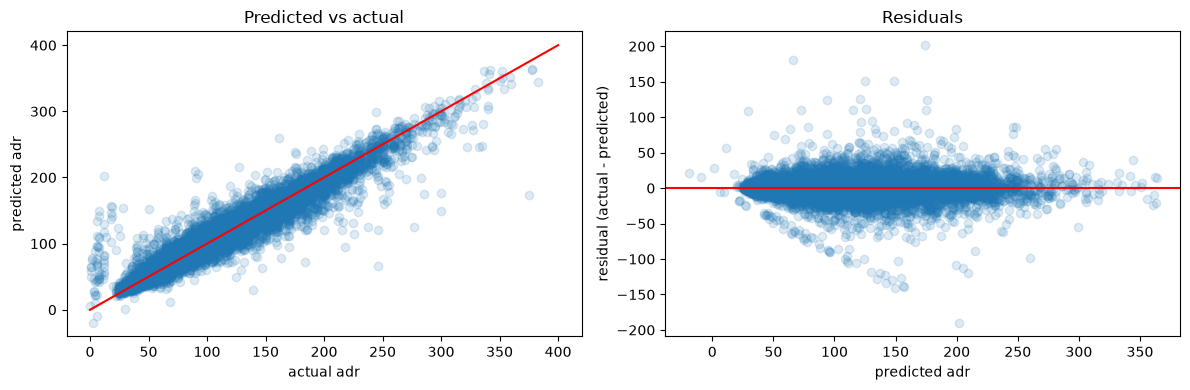

                  mean  count
adr                          
(0, 60]       7.860765   2532
(60, 100]     7.224049   6237
(100, 150]    9.082318   5288
(150, 200]   12.369697   2079
(200, 1000]  16.975106    903


In [27]:
resid = y_test - pred

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(y_test, pred, alpha=0.15)
ax[0].plot([0, 400], [0, 400], "r")
ax[0].set(xlabel="actual adr", ylabel="predicted adr", title="Predicted vs actual")

ax[1].scatter(pred, resid, alpha=0.15)
ax[1].axhline(0, color="r")
ax[1].set(xlabel="predicted adr", ylabel="residual (actual - predicted)", title="Residuals")
plt.tight_layout(); plt.show()

# MAE by price band
bands = pd.cut(y_test, [0, 60, 100, 150, 200, 1000])
print(resid.abs().groupby(bands, observed=True).agg(["mean", "count"]))

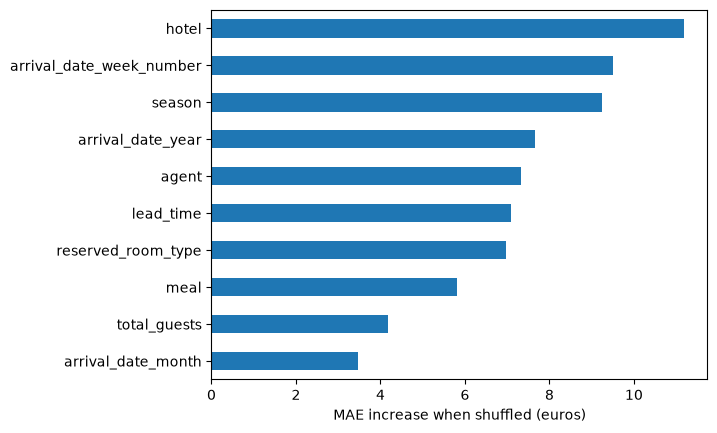

In [28]:
from sklearn.inspection import permutation_importance

sub = X_test.sample(5000, random_state=RANDOM_STATE)
perm = permutation_importance(best_pipe, sub, y_test.loc[sub.index],
                              scoring="neg_mean_absolute_error",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)

imp = pd.Series(perm.importances_mean, index=sub.columns).sort_values(ascending=False)
imp.head(10).plot.barh().invert_yaxis()
plt.xlabel("MAE increase when shuffled (euros)"); plt.show()

In [29]:
import joblib, os
os.makedirs("../models", exist_ok=True)
joblib.dump(best_pipe, "../models/price_model.pkl")

import sklearn
print("scikit-learn", sklearn.__version__)   # record the version the model was saved with

['../models/price_model.pkl']

### Final evaluation (test set, scored once)

Tuned Hist Gradient Boosting on the held-out test set: **MAE 9.04, RMSE 14.21, R² 0.919**. This matches the CV result (MAE 9.39), so the estimate is stable and there is no sign of leakage. A suggested nightly rate is typically within about 9 euros of the actual rate, and the model explains about 92% of the variation in prices.

**Error by price band (test MAE).**
| Actual adr | MAE | Bookings |
|---|---|---|
| 0-60 | 7.86 | 2,532 |
| 60-100 | 7.22 | 6,237 |
| 100-150 | 9.08 | 5,288 |
| 150-200 | 12.37 | 2,079 |
| 200+ | 16.98 | 903 |

**Where it fails.**
- The error grows with the price: from about 7 euros for mid-range rooms to about 17 for bookings above 200, which matches the fan-shaped residual plot. High-priced peak bookings are the least reliable, and these are also the ones with the most revenue at stake.
- In relative terms the picture is different. The cheapest band (under 60) already has an error of at least 13% of the price, while the 200+ band is under 9%, so cheap bookings are the hardest proportionally.
- A handful of bookings with a very low actual price (near 0-20) are predicted at 100-200 euros, probably special or discounted deals that the booking details cannot reveal. A few predictions are slightly negative and should be clipped at 0.

**What drives price.** Permutation importance ranks hotel type first, followed by the time of year (week number, season, month and year together) and the booking channel (agent), then lead time and room type. Party size matters little. Seasonal columns overlap, so each one understates how important seasonality is as a whole. The year effect reflects price growth over 2015-2017 and cannot be extrapolated to future years.

**Business use.** The model works well as a rate suggestion for typical bookings (under 150 euros, error about 7-9 euros). For peak-season or premium bookings the manager should treat the suggestion as a starting point.

**Deployment notes (saved model).**
- If `build_preprocessor` uses any custom classes or functions from `src`, the Streamlit app must be able to import them from the same module path when it loads `price_model.pkl`.
- Load the file with the same scikit-learn version it was saved with (printed in the save cell); pickles can break across versions.
- The model can output a few negative prices, so clip predictions at 0 in the app: `np.clip(pred, 0, None)`.
